# DineScope — Task 03: Cuisine Classification

## Verification, Evaluation & Demonstration

This notebook verifies the outputs created by the Python implementation in `src/`. It loads the saved processed datasets, trained artifacts, predictions, evaluation reports and visualizations. It does not retrain models or retune the classification threshold.

## 1. Setup and project paths
Run from the project root or the `notebooks/` folder.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Image
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    hamming_loss,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the DineScope project root.
def find_project_root() -> Path:
    cwd = Path.cwd()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the DineScope project root. "
        "Run this notebook from DineScope or its notebooks folder."
    )

PROJECT_ROOT = find_project_root()

# Task 3 directories.
DATA = PROJECT_ROOT / "data" / "processed" / "task_3_cuisine_classification"
MODELS = PROJECT_ROOT / "models" / "task_3"
REPORTS = PROJECT_ROOT / "reports" / "task_3"
FIGURES = PROJECT_ROOT / "outputs" / "figures" / "task_3"

print("=" * 75)
print("DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS")
print("TASK 03: CUISINE CLASSIFICATION")
print("NOTEBOOK: CUISINE CLASSIFICATION VERIFICATION")
print("=" * 75)

print("Project root:", PROJECT_ROOT)
print("Data:", DATA)
print("Models:", MODELS)
print("Reports:", REPORTS)
print("Figures:", FIGURES)

print("\nProject directories validated successfully.")

DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 03: CUISINE CLASSIFICATION
NOTEBOOK: CUISINE CLASSIFICATION VERIFICATION
Project root: c:\Users\kamal\OneDrive\Desktop\DineScope
Data: c:\Users\kamal\OneDrive\Desktop\DineScope\data\processed\task_3_cuisine_classification
Models: c:\Users\kamal\OneDrive\Desktop\DineScope\models\task_3
Reports: c:\Users\kamal\OneDrive\Desktop\DineScope\reports\task_3
Figures: c:\Users\kamal\OneDrive\Desktop\DineScope\outputs\figures\task_3

Project directories validated successfully.


## 2. Check expected artifacts

Verify that the processed train/test datasets, model artifacts, prediction outputs and final reports from Programs 02–08 are available before loading them.

In [2]:
expected = [
    DATA / "cuisine_X_train.csv",
    DATA / "cuisine_X_test.csv",
    DATA / "cuisine_y_train.csv",
    DATA / "cuisine_y_test.csv",
    DATA / "cuisine_X_train_engineered.npz",
    DATA / "cuisine_X_test_engineered.npz",
    DATA / "cuisine_best_model_predictions.npy",
    DATA / "cuisine_tuned_test_predictions.npy",
    DATA / "cuisine_pipeline_predictions.npy",
    DATA / "cuisine_pipeline_probabilities.npy",
    MODELS / "cuisine_feature_preprocessor.joblib",
    MODELS / "tuned_cuisine_classification_model.joblib",
    MODELS / "cuisine_classification_threshold.joblib",
    REPORTS / "cuisine_label_mapping.csv",
    REPORTS / "cuisine_model_comparison.csv",
    REPORTS / "cuisine_threshold_comparison.csv",
    REPORTS / "cuisine_threshold_tuning_summary.csv",
    REPORTS / "cuisine_final_model_comparison.csv",
    REPORTS / "cuisine_final_classification_summary.csv",
]

missing_files = [path for path in expected if not path.exists()]

if missing_files:
    print("Missing required artifacts:")
    for path in missing_files:
        print("-", path)
    raise FileNotFoundError(
        "Run the corresponding Task 3 programs before executing this notebook."
    )

print(f"All {len(expected)} required Task 3 artifacts are available.")

All 19 required Task 3 artifacts are available.


## 3. Verify processed training and test data

The classification workflow retains the train/test split created during preprocessing. Cuisine targets are stored separately from restaurant input features.

In [3]:
train_features_path = DATA / "cuisine_X_train.csv"
test_features_path = DATA / "cuisine_X_test.csv"
train_targets_path = DATA / "cuisine_y_train.csv"
test_targets_path = DATA / "cuisine_y_test.csv"

X_train_df = pd.read_csv(train_features_path)
X_test_df = pd.read_csv(test_features_path)
y_train_df = pd.read_csv(train_targets_path)
y_test_df = pd.read_csv(test_targets_path)

print("Training feature data:", X_train_df.shape)
print("Test feature data:", X_test_df.shape)
print("Training target data:", y_train_df.shape)
print("Test target data:", y_test_df.shape)

assert len(X_train_df) == len(y_train_df)
assert len(X_test_df) == len(y_test_df)
assert "Source Row Index" in X_train_df.columns
assert "Source Row Index" in X_test_df.columns
assert X_train_df["Source Row Index"].is_unique
assert X_test_df["Source Row Index"].is_unique
assert "Cuisines" not in X_train_df.columns
assert "Cuisines" not in X_test_df.columns

display(pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Feature rows": [len(X_train_df), len(X_test_df)],
    "Feature columns": [X_train_df.shape[1], X_test_df.shape[1]],
    "Target rows": [len(y_train_df), len(y_test_df)],
    "Target columns": [y_train_df.shape[1] - 1, y_test_df.shape[1] - 1],
}))

Training feature data: (7621, 21)
Test feature data: (1921, 21)
Training target data: (7621, 146)
Test target data: (1921, 146)


,Dataset,Feature rows,Feature columns,Target rows,Target columns
0,Training,7621,21,7621,145
1,Testing,1921,21,1921,145


### 3.1 Feature configuration

The model uses 13 restaurant input features: seven categorical and six numerical. The cuisine labels and source row index are not model input features.

In [4]:
CATEGORICAL_FEATURES = [
    "Country Code",
    "City",
    "Currency",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now",
    "Switch to order menu",
]

NUMERICAL_FEATURES = [
    "Longitude",
    "Latitude",
    "Average Cost for two",
    "Price range",
    "Aggregate rating",
    "Votes",
]

SELECTED_FEATURES = CATEGORICAL_FEATURES + NUMERICAL_FEATURES

feature_configuration = pd.DataFrame({
    "Feature Type": ["Categorical"] * len(CATEGORICAL_FEATURES)
                    + ["Numerical"] * len(NUMERICAL_FEATURES),
    "Feature": SELECTED_FEATURES,
})

display(feature_configuration)
print("Total input features:", len(SELECTED_FEATURES))

,Feature Type,Feature
0,Categorical,Country Code
1,Categorical,City
2,Categorical,Currency
3,Categorical,Has Table booking
4,Categorical,Has Online delivery
5,Categorical,Is delivering now
6,Categorical,Switch to order menu
7,Numerical,Longitude
8,Numerical,Latitude
9,Numerical,Average Cost for two


Total input features: 13


## 4. Load final trained models

Load the saved feature preprocessor, tuned One-vs-Rest Logistic Regression model, threshold and label mapping. Loading these artifacts does not retrain the model.

In [5]:
y_test = np.load(DATA / "cuisine_y_test.npy")
baseline_predictions = np.load(DATA / "cuisine_best_model_predictions.npy")
tuned_predictions = np.load(DATA / "cuisine_tuned_test_predictions.npy")
pipeline_predictions = np.load(DATA / "cuisine_pipeline_predictions.npy")
probabilities = np.load(DATA / "cuisine_pipeline_probabilities.npy")

label_mapping = pd.read_csv(REPORTS / "cuisine_label_mapping.csv")
cuisine_classes = label_mapping["Cuisine Label"].astype(str).tolist()

preprocessor = joblib.load(MODELS / "cuisine_feature_preprocessor.joblib")
tuned_model = joblib.load(MODELS / "tuned_cuisine_classification_model.joblib")
threshold = float(joblib.load(MODELS / "cuisine_classification_threshold.joblib"))

print("Test target matrix:", y_test.shape)
print("Baseline predictions:", baseline_predictions.shape)
print("Tuned predictions:", tuned_predictions.shape)
print("Pipeline predictions:", pipeline_predictions.shape)
print("Probability matrix:", probabilities.shape)
print("Cuisine classes:", len(cuisine_classes))
print("Selected threshold:", threshold)

Test target matrix: (1921, 145)
Baseline predictions: (1921, 145)
Tuned predictions: (1921, 145)
Pipeline predictions: (1921, 145)
Probability matrix: (1921, 145)
Cuisine classes: 145
Selected threshold: 0.225


## 5. Review initial algorithm comparison

Program 04 compared the baseline multi-label classification algorithms. Review the saved comparison report to see the model selection results before threshold tuning.

In [6]:
path = REPORTS / "cuisine_model_comparison.csv"
if path.exists():
    initial_comparison = pd.read_csv(path)
    display(initial_comparison)
else:
    print("Initial cuisine model comparison report not found.")

,Model Rank,Model,Micro Precision,Micro Recall,Micro F1,Macro F1 - All Classes,Macro F1 - Test Supported,Weighted F1,Subset Accuracy,Hamming Loss,Predicted Labels
0,1,Logistic Regression,0.558544,0.089617,0.154452,0.010491,0.013228,0.121142,0.015617,0.013876,632
1,2,Linear SVM,0.554662,0.087586,0.151283,0.020088,0.025328,0.118836,0.015617,0.013897,622


## 6. Final model evaluation

Metrics are recalculated from the saved held-out test targets and prediction matrices. The notebook does not fit or retune a model.

In [7]:
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Micro Precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "Micro Recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "Micro F1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "Macro F1 All Classes": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Subset Accuracy": accuracy_score(y_true, y_pred),
        "Hamming Loss": hamming_loss(y_true, y_pred),
        "Predicted Labels": int(y_pred.sum()),
    }

model_comparison = pd.DataFrame([
    calculate_metrics(y_test, baseline_predictions, "Baseline Logistic Regression"),
    calculate_metrics(y_test, tuned_predictions, "Tuned Logistic Regression"),
])
display(model_comparison.style.format({
    c: "{:.4f}" for c in model_comparison.select_dtypes(include="number").columns
}))

,Model,Micro Precision,Micro Recall,Micro F1,Macro F1 All Classes,Weighted F1,Subset Accuracy,Hamming Loss,Predicted Labels
0,Baseline Logistic Regression,0.5585,0.0896,0.1545,0.0105,0.1211,0.0156,0.0139,632.0000
1,Tuned Logistic Regression,0.3628,0.4775,0.4124,0.0706,0.3177,0.0432,0.0192,5184.0000


### 6.1 Reported tuned-model results

The saved Program 08 comparison report provides the consolidated final evaluation. The table below is independently reconstructed from the stored predictions.

In [8]:
evaluation_path = REPORTS / "cuisine_final_model_comparison.csv"
if evaluation_path.exists():
    reported_evaluation = pd.read_csv(evaluation_path)
    display(reported_evaluation)
else:
    print("Final model comparison report not found. Run Program 08.")

,Model,Micro Precision,Micro Recall,Micro F1,Macro F1 All Classes,Macro F1 Test-Supported,Weighted F1,Subset Accuracy,Hamming Loss,Predicted Labels,Actual Positive Labels,True Positives,False Positives,False Negatives,True Negatives
0,Baseline Logistic Regression,0.558544,0.089617,0.154452,0.010491,0.013228,0.121142,0.015617,0.013876,632,3939,353,279,3586,274327
1,Tuned Logistic Regression,0.362847,0.477532,0.412364,0.070631,0.089056,0.317695,0.043207,0.019246,5184,3939,1881,3303,2058,271303


### 6.2 Interpretation

The tuned model improves Micro F1 and recall compared with the baseline. Precision decreases and Hamming Loss increases, showing the precision-recall trade-off created by the selected global threshold. These metrics describe the held-out test split, not external validation.

## 7. Verify final model selection

Review the threshold tuning outputs from Program 05. The selected global threshold was chosen using the validation split and was not selected using the held-out test set.

In [9]:
for filename in [
    "cuisine_threshold_tuning_summary.csv",
    "cuisine_threshold_comparison.csv",
]:
    path = REPORTS / filename
    print("\n", filename)
    if path.exists():
        display(pd.read_csv(path))
    else:
        print("Report not found:", path)

print("Loaded selected threshold:", threshold)


 cuisine_threshold_tuning_summary.csv


,Metric,Value
0,Original Training Records,7621
1,Sub-training Records,6097
2,Validation Records,1524
3,Cuisine Classes,145
4,Model,Logistic Regression
5,Classification Strategy,OneVsRestClassifier
6,Threshold Search Range,0.05 to 0.50
7,Threshold Search Step,0.025
8,Selected Threshold,0.225
9,Validation Micro Precision,0.36032093362509116



 cuisine_threshold_comparison.csv


,Threshold,Micro Precision,Micro Recall,Micro F1,Macro F1,Hamming Loss,Predicted Labels
0,0.225,0.360321,0.476221,0.410242,0.057003,0.019282,4113
1,0.200,0.344896,0.504820,0.409808,0.064764,0.020477,4555
2,0.175,0.329909,0.536632,0.408613,0.073794,0.021875,5062
3,0.250,0.377117,0.436375,0.404588,0.055610,0.018088,3601
4,0.150,0.313412,0.566195,0.403481,0.079999,0.023577,5622
5,0.275,0.389692,0.398458,0.394026,0.053155,0.017259,3182
6,0.125,0.282531,0.607005,0.385589,0.079524,0.027242,6686
7,0.300,0.406445,0.356684,0.379942,0.049014,0.016395,2731
8,0.325,0.426209,0.322943,0.367459,0.047508,0.015658,2358
9,0.100,0.249240,0.658419,0.361599,0.090721,0.032741,8221


Loaded selected threshold: 0.225


## 8. Run inference with the saved model

Predictions are generated from the feature-only held-out test file. Cuisine target labels are not loaded as model inputs. No model is trained in this notebook.

In [10]:
inference_path = DATA / "cuisine_X_test.csv"
if not inference_path.exists():
    raise FileNotFoundError(f"Missing inference input: {inference_path}")

inference_input = pd.read_csv(inference_path)
categorical_features = [
    "Country Code", "City", "Currency", "Has Table booking",
    "Has Online delivery", "Is delivering now", "Switch to order menu"
]
numerical_features = [
    "Longitude", "Latitude", "Average Cost for two",
    "Price range", "Aggregate rating", "Votes"
]
selected_features = categorical_features + numerical_features

assert "Source Row Index" in inference_input.columns
assert "Cuisines" not in inference_input.columns

source_row_indices = inference_input["Source Row Index"].to_numpy()
X_inference = inference_input[selected_features].copy()

for column in numerical_features:
    X_inference[column] = pd.to_numeric(X_inference[column], errors="coerce")
    X_inference[column] = X_inference[column].replace([np.inf, -np.inf], np.nan)

for column in ["Average Cost for two", "Votes"]:
    X_inference[column] = np.log1p(X_inference[column].clip(lower=0))

for column in categorical_features:
    X_inference[column] = X_inference[column].fillna("Unknown").astype(str)

X_engineered = preprocessor.transform(X_inference)
inference_probabilities = np.asarray(tuned_model.predict_proba(X_engineered), dtype=np.float64)
inference_predictions = (inference_probabilities >= threshold).astype(np.uint8)

assert inference_probabilities.shape == (len(inference_input), len(cuisine_classes))
assert np.array_equal(inference_predictions, pipeline_predictions)

print("Input records:", len(inference_input))
print("Input features:", len(selected_features))
print("Engineered features:", X_engineered.shape[1])
print("Cuisine classes:", len(cuisine_classes))
print("Threshold:", threshold)
print("Predicted cuisine labels:", int(inference_predictions.sum()))
print("Exact agreement with Program 07:",
      f"{np.mean(inference_predictions == pipeline_predictions) * 100:.2f}%")

Input records: 1921
Input features: 13
Engineered features: 170
Cuisine classes: 145
Threshold: 0.225
Predicted cuisine labels: 5184
Exact agreement with Program 07: 100.00%


### 8.1 Prediction validity checks

Check prediction dimensions, probability ranges, source-row traceability and exact agreement with Program 07.

In [11]:
prediction_checks = {
    "Prediction matrix dimensions": inference_predictions.shape == (len(inference_input), len(cuisine_classes)),
    "Probability matrix dimensions": inference_probabilities.shape == (len(inference_input), len(cuisine_classes)),
    "Predictions are binary": np.isin(inference_predictions, [0, 1]).all(),
    "Probabilities are finite": np.isfinite(inference_probabilities).all(),
    "Probabilities are within [0, 1]": ((inference_probabilities >= 0) & (inference_probabilities <= 1)).all(),
    "Notebook predictions match Program 07": np.array_equal(inference_predictions, pipeline_predictions),
    "Program 06 predictions match Program 07": np.array_equal(tuned_predictions, pipeline_predictions),
}
display(pd.DataFrame({
    "Check": list(prediction_checks.keys()),
    "Status": ["PASS" if value else "FAIL" for value in prediction_checks.values()],
}))
if not all(prediction_checks.values()):
    raise AssertionError("One or more inference validity checks failed.")

,Check,Status
0,Prediction matrix dimensions,PASS
1,Probability matrix dimensions,PASS
2,Predictions are binary,PASS
3,Probabilities are finite,PASS
4,"Probabilities are within [0, 1]",PASS
5,Notebook predictions match Program 07,PASS
6,Program 06 predictions match Program 07,PASS


## 9. Per-cuisine classification analysis

Review precision, recall and F1 for each cuisine. Rare and absent classes are marked separately because their evaluation support differs.

In [12]:
base_p, base_r, base_f1, support = precision_recall_fscore_support(
    y_test, baseline_predictions, average=None, zero_division=0
)
tuned_p, tuned_r, tuned_f1, _ = precision_recall_fscore_support(
    y_test, tuned_predictions, average=None, zero_division=0
)

per_class_metrics = pd.DataFrame({
    "Cuisine": cuisine_classes,
    "Test Support": support,
    "Baseline Precision": base_p,
    "Baseline Recall": base_r,
    "Baseline F1": base_f1,
    "Tuned Precision": tuned_p,
    "Tuned Recall": tuned_r,
    "Tuned F1": tuned_f1,
})
per_class_metrics["F1 Improvement"] = per_class_metrics["Tuned F1"] - per_class_metrics["Baseline F1"]
per_class_metrics["Class Category"] = np.where(
    per_class_metrics["Test Support"] == 0, "Absent from test",
    np.where(per_class_metrics["Test Support"] < 10, "Rare", "Common")
)
per_class_metrics = per_class_metrics.sort_values("Test Support", ascending=False)
display(per_class_metrics.head(25).style.format({
    c: "{:.4f}" for c in per_class_metrics.select_dtypes(include="number").columns
}))

,Cuisine,Test Support,Baseline Precision,Baseline Recall,Baseline F1,Tuned Precision,Tuned Recall,Tuned F1,F1 Improvement,Class Category
100,north indian,792.0000,0.5966,0.3548,0.4450,0.4557,0.9924,0.6246,0.1796,Common
34,chinese,547.0000,0.5000,0.0731,0.1276,0.3526,0.9378,0.5125,0.3849,Common
49,fast food,397.0000,0.1429,0.0025,0.0050,0.2898,0.7103,0.4117,0.4067,Common
95,mughlai,199.0000,0.0000,0.0000,0.0000,0.1695,0.1005,0.1262,0.1262,Common
70,italian,153.0000,0.5833,0.0458,0.0848,0.2624,0.3464,0.2986,0.2137,Common
12,bakery,149.0000,0.0000,0.0000,0.0000,0.1429,0.0067,0.0128,0.0128,Common
37,continental,147.0000,0.4118,0.0952,0.1547,0.3578,0.5306,0.4274,0.2727,Common
27,cafe,141.0000,0.0000,0.0000,0.0000,0.3750,0.2128,0.2715,0.2715,Common
42,desserts,131.0000,0.0000,0.0000,0.0000,0.2500,0.0305,0.0544,0.0544,Common
123,south indian,127.0000,0.0000,0.0000,0.0000,0.7500,0.0236,0.0458,0.0458,Common


## 10. Prediction distribution analysis

Compare actual test label counts with baseline and tuned predicted counts. High prediction frequency alone does not establish classification quality.

In [13]:
prediction_distribution = pd.DataFrame({
    "Cuisine": cuisine_classes,
    "Actual Count": y_test.sum(axis=0),
    "Baseline Predicted Count": baseline_predictions.sum(axis=0),
    "Tuned Predicted Count": tuned_predictions.sum(axis=0),
}).sort_values("Tuned Predicted Count", ascending=False)
display(prediction_distribution.head(20))

,Cuisine,Actual Count,Baseline Predicted Count,Tuned Predicted Count
100,north indian,792,471,1725
34,chinese,547,80,1455
49,fast food,397,7,973
37,continental,147,34,218
70,italian,153,12,202
95,mughlai,199,0,118
27,cafe,141,0,80
129,street food,112,2,80
2,american,78,9,67
118,seafood,35,5,28


## 11. Review prediction coverage and threshold behaviour

Summarize how many restaurants received at least one predicted cuisine, how many received none, and the average number of predicted labels.

In [14]:
counts_per_restaurant = inference_predictions.sum(axis=1)
with_predictions = int((counts_per_restaurant > 0).sum())
without_predictions = int((counts_per_restaurant == 0).sum())
selected_probabilities = inference_probabilities[inference_predictions == 1]

prediction_summary = pd.DataFrame({
    "Metric": [
        "Restaurants processed",
        "Restaurants with at least one predicted cuisine",
        "Restaurants with no predicted cuisine",
        "Total predicted cuisine labels",
        "Average predicted cuisines per restaurant",
        "Selected threshold",
        "Average maximum probability estimate",
        "Average probability estimate among predicted labels",
    ],
    "Value": [
        len(inference_input), with_predictions, without_predictions,
        int(inference_predictions.sum()), float(counts_per_restaurant.mean()),
        threshold, float(inference_probabilities.max(axis=1).mean()),
        float(selected_probabilities.mean()) if selected_probabilities.size else np.nan,
    ]
})
display(prediction_summary)

,Metric,Value
0,Restaurants processed,1921.000000
1,Restaurants with at least one predicted cuisine,1877.000000
2,Restaurants with no predicted cuisine,44.000000
3,Total predicted cuisine labels,5184.000000
4,Average predicted cuisines per restaurant,2.698594
5,Selected threshold,0.225000
6,Average maximum probability estimate,0.451023
7,Average probability estimate among predicted l...,0.367658


## 12. Display saved evaluation figures

These figures were generated by Program 08. The notebook displays the saved images rather than recomputing or changing the plots.

01_cuisine_model_performance_comparison.png


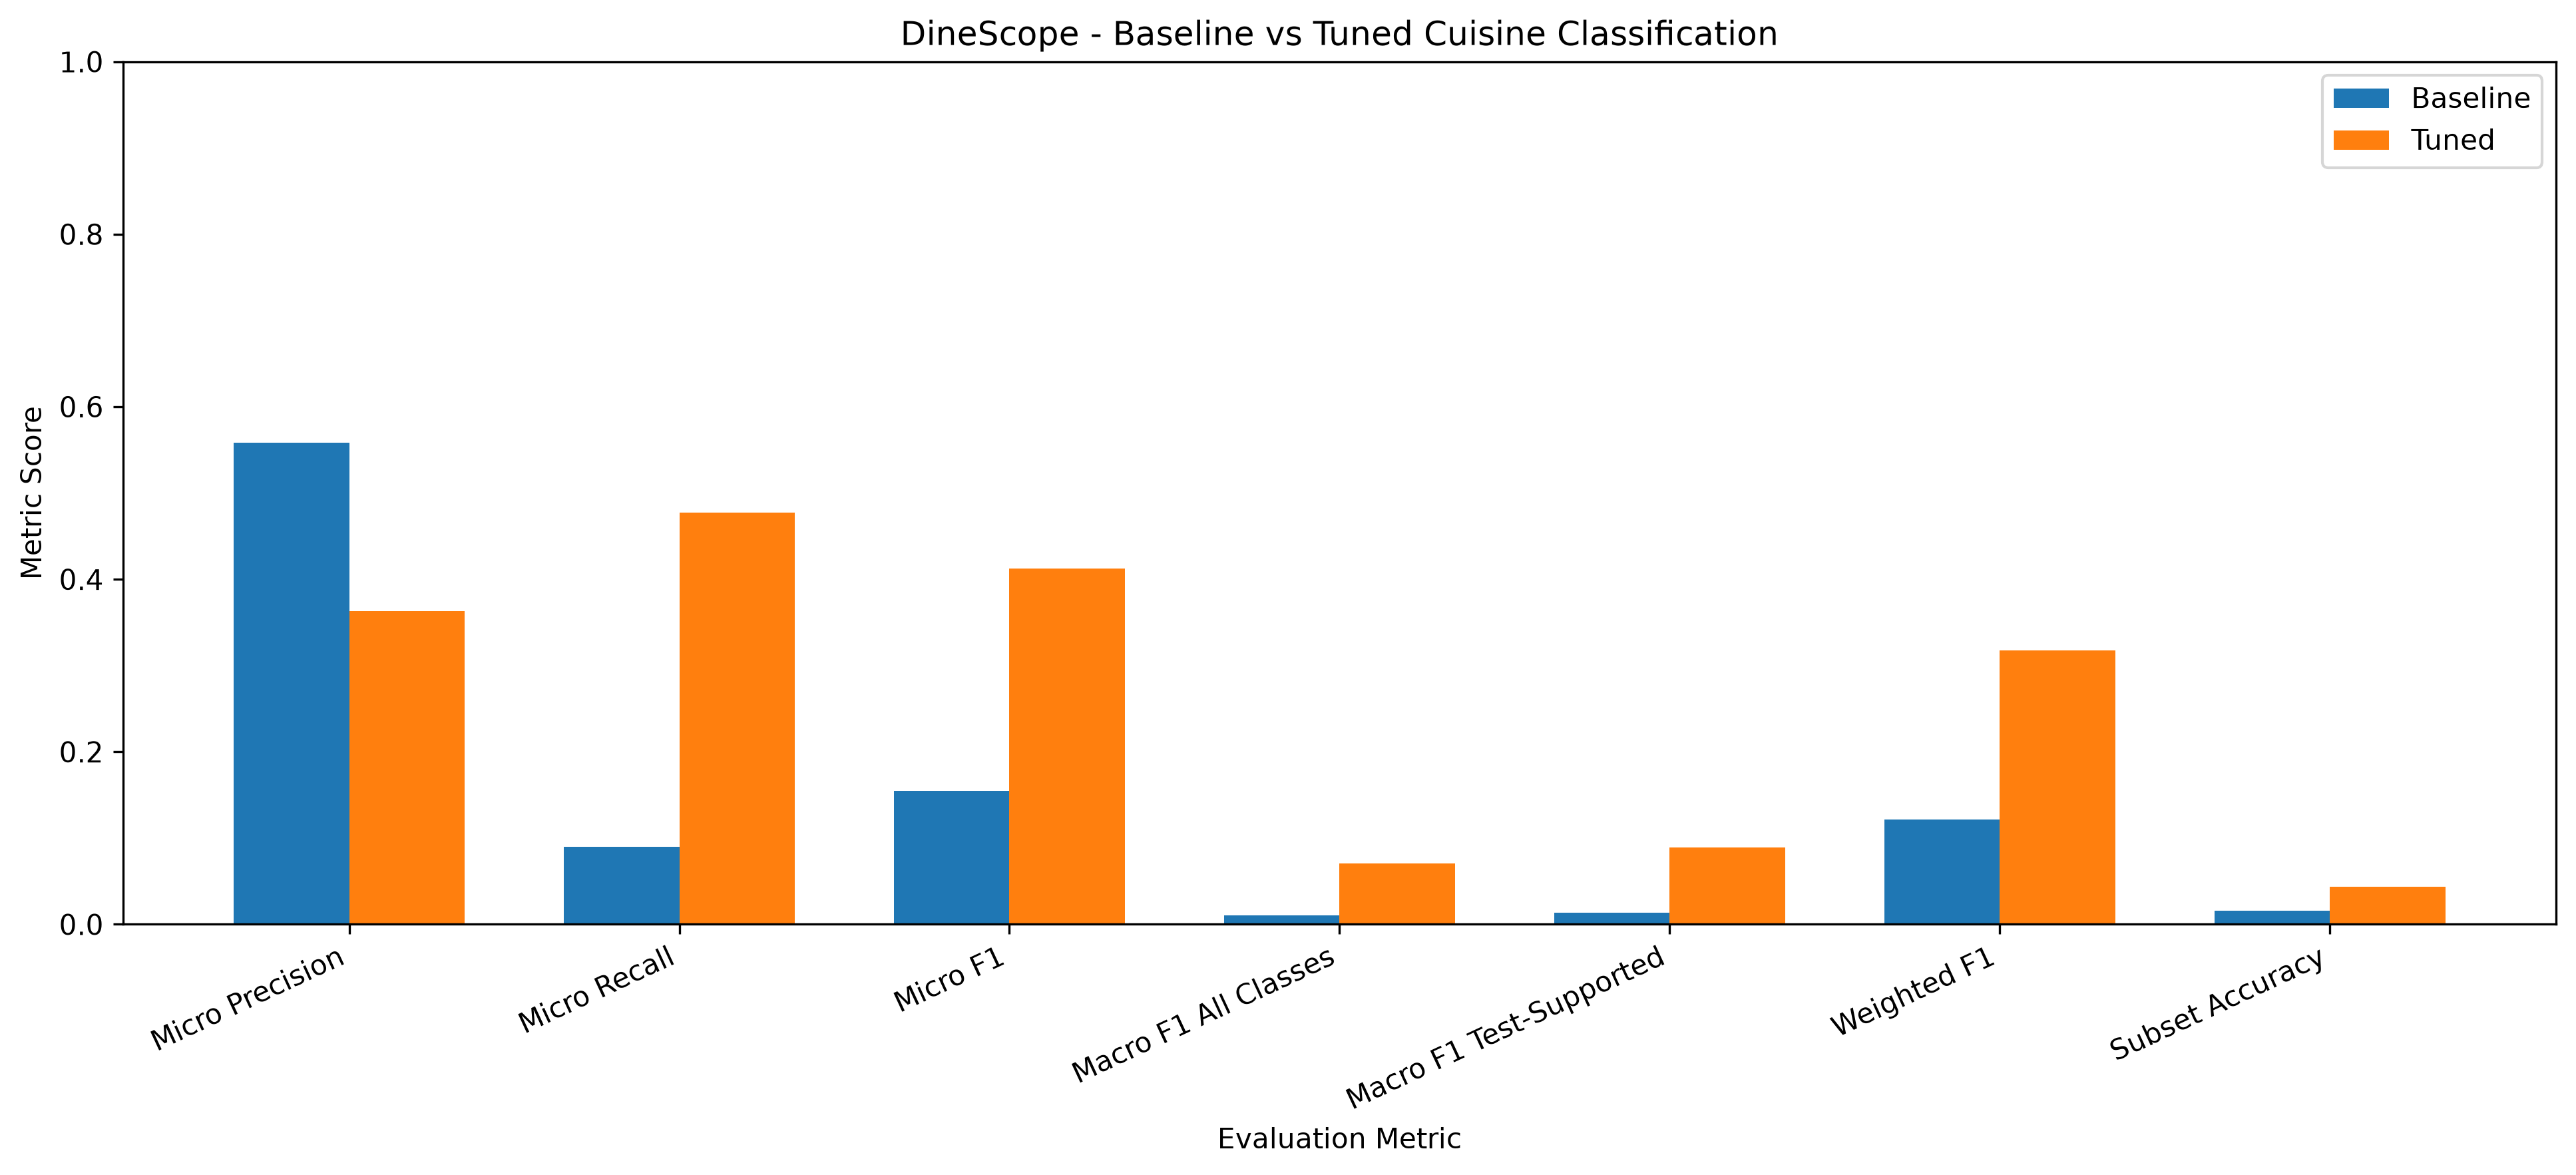

02_cuisine_per_class_f1_comparison.png


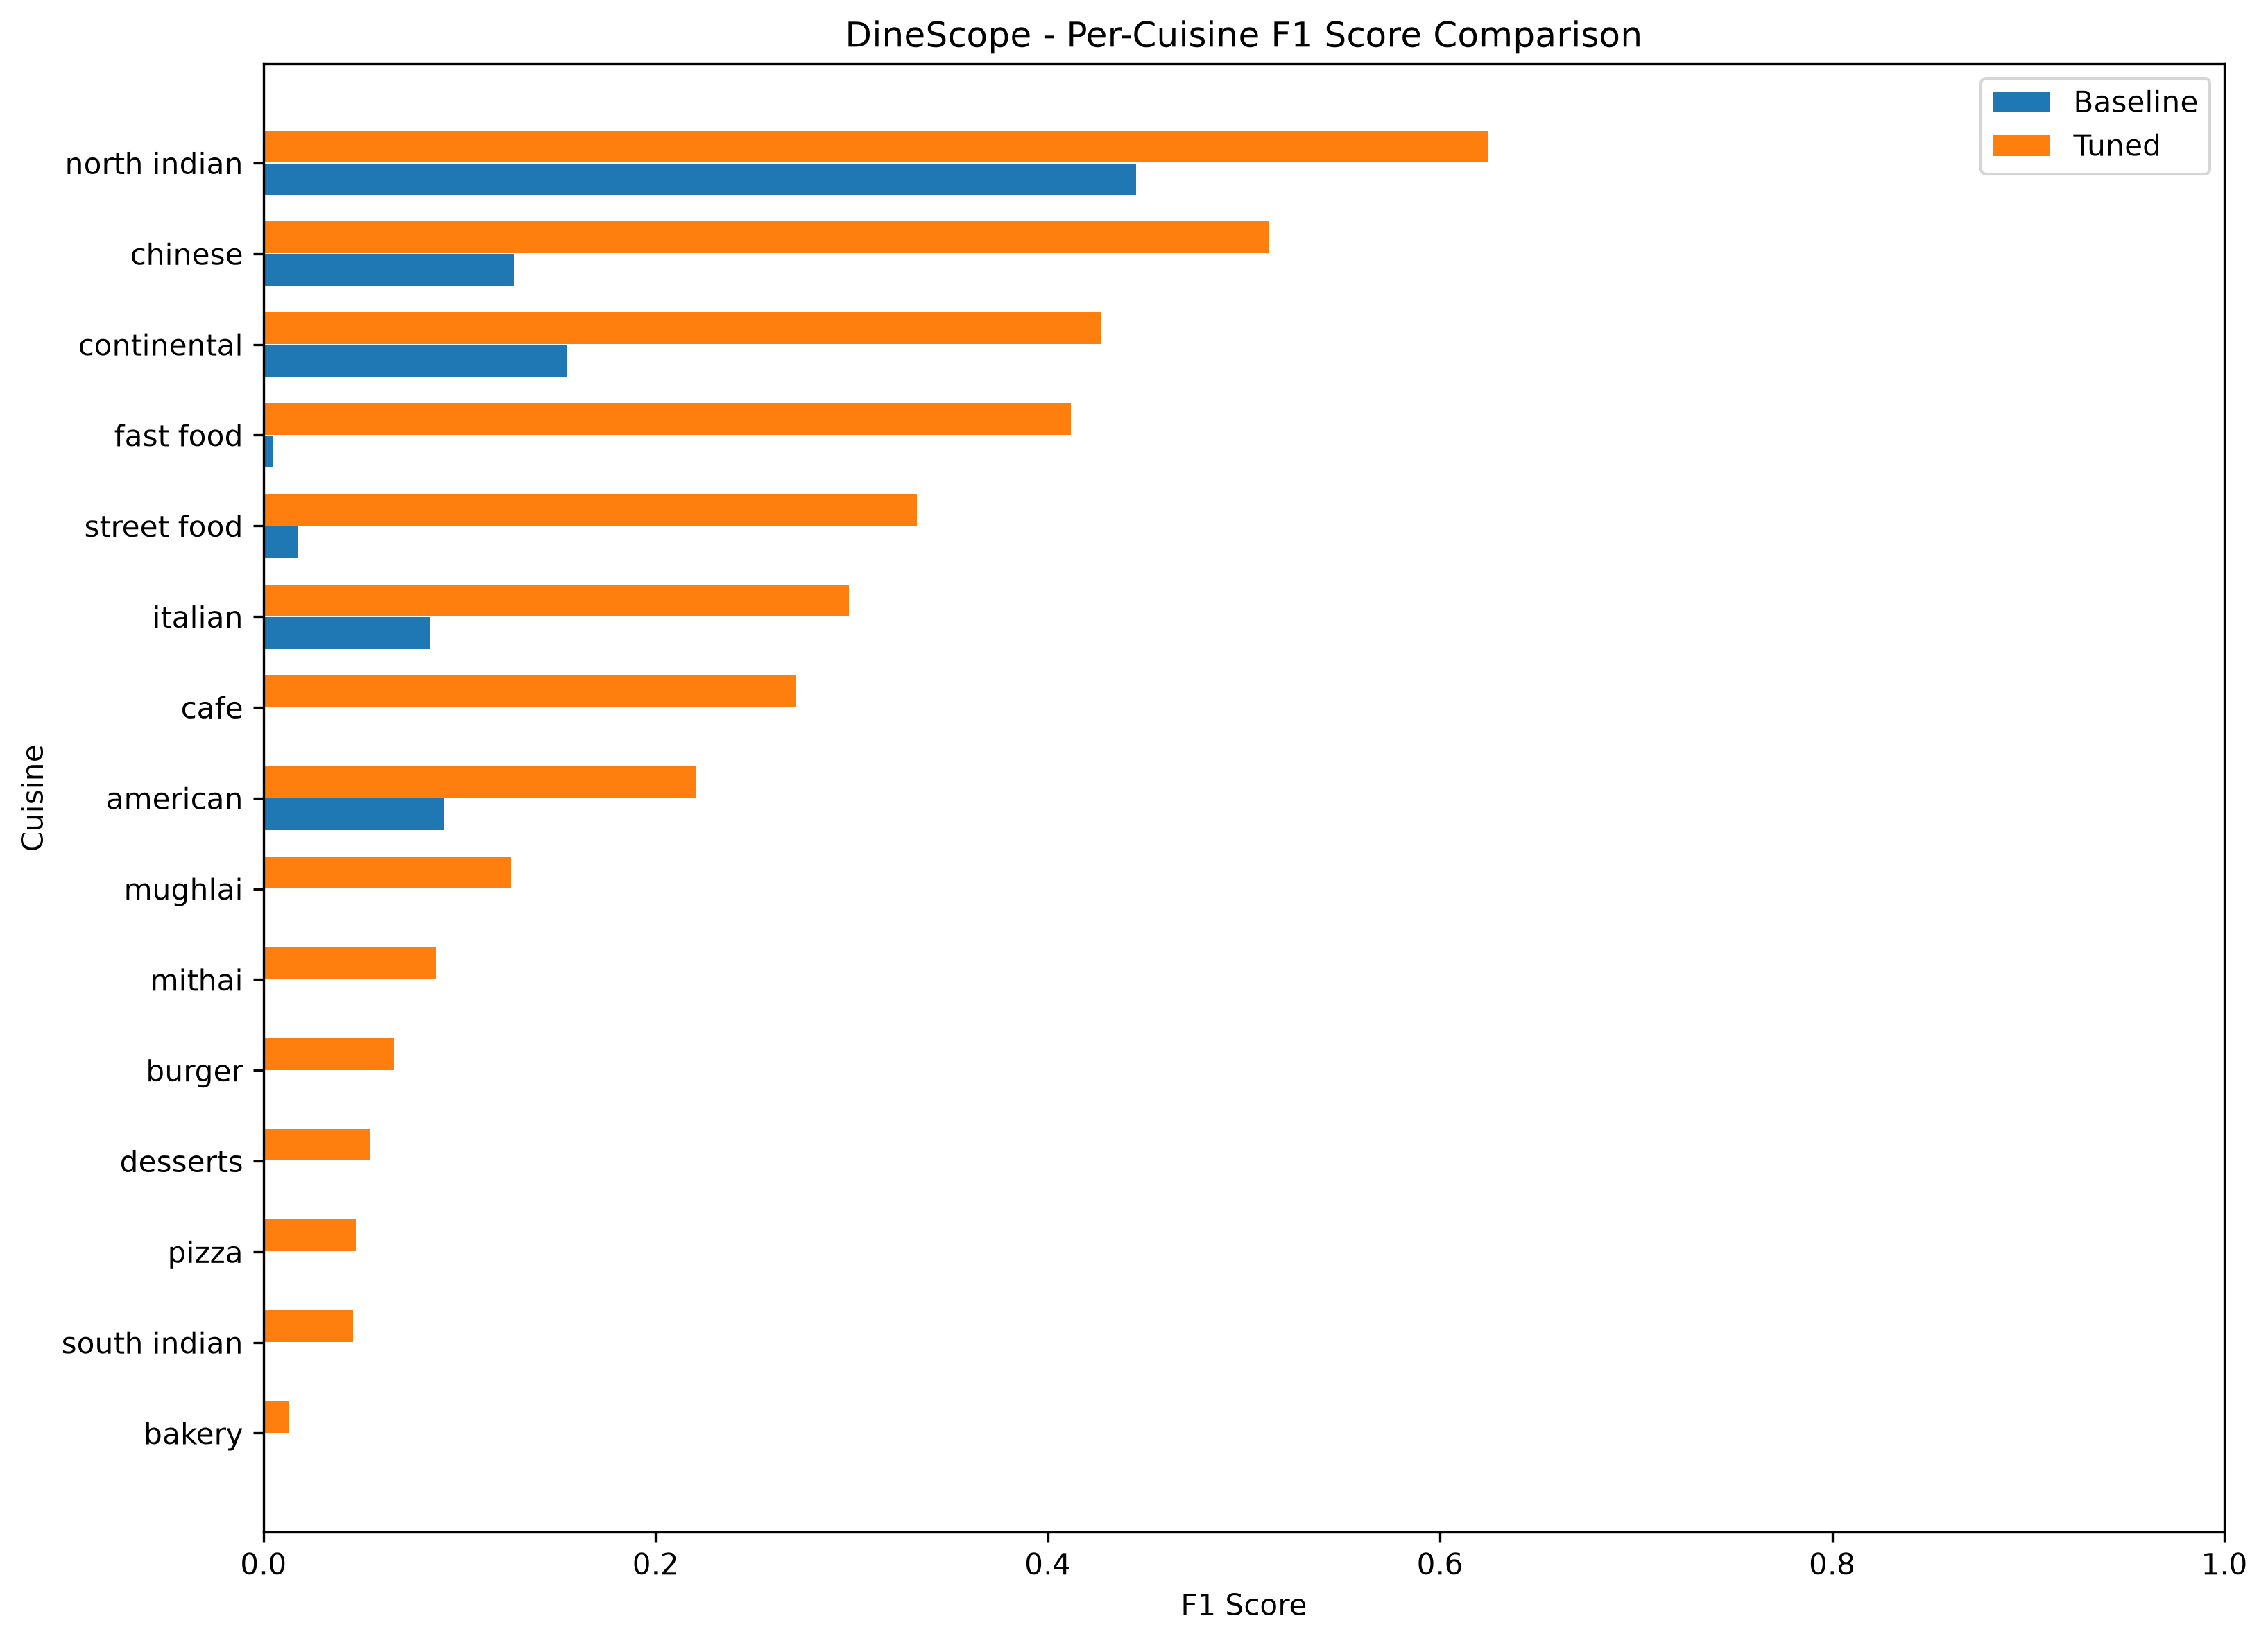

03_cuisine_support_vs_f1.png


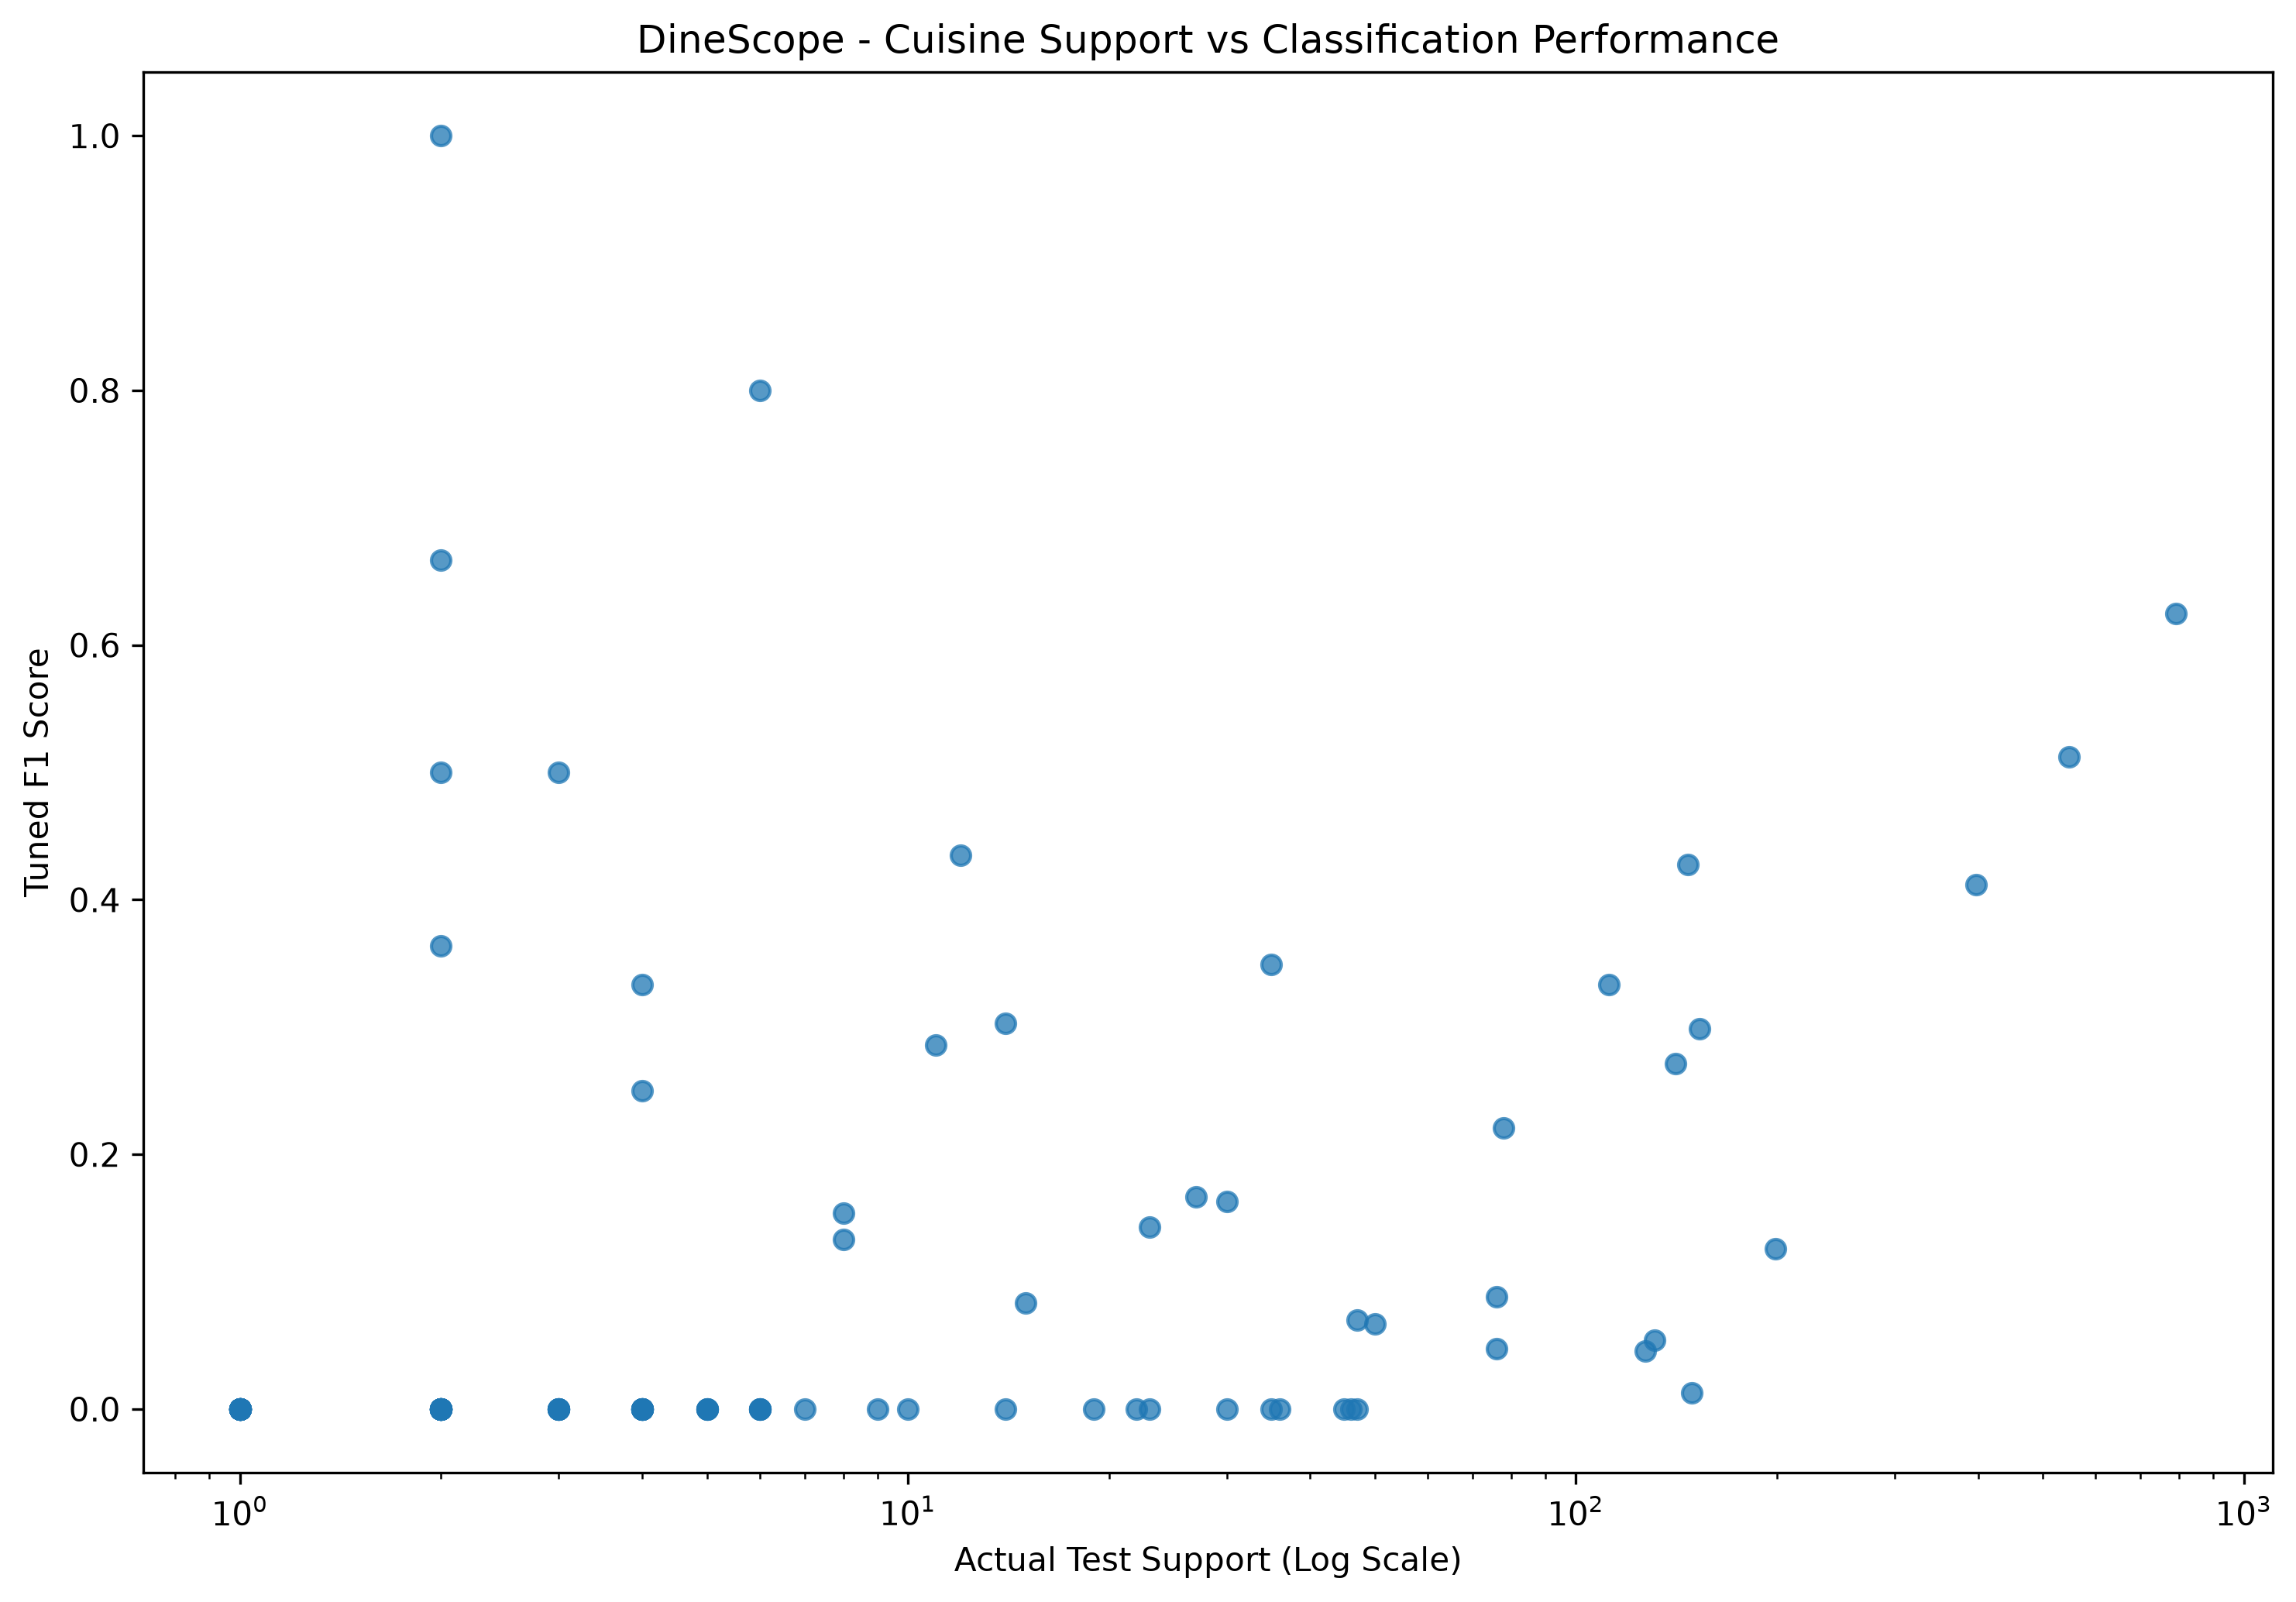

04_cuisine_prediction_distribution.png


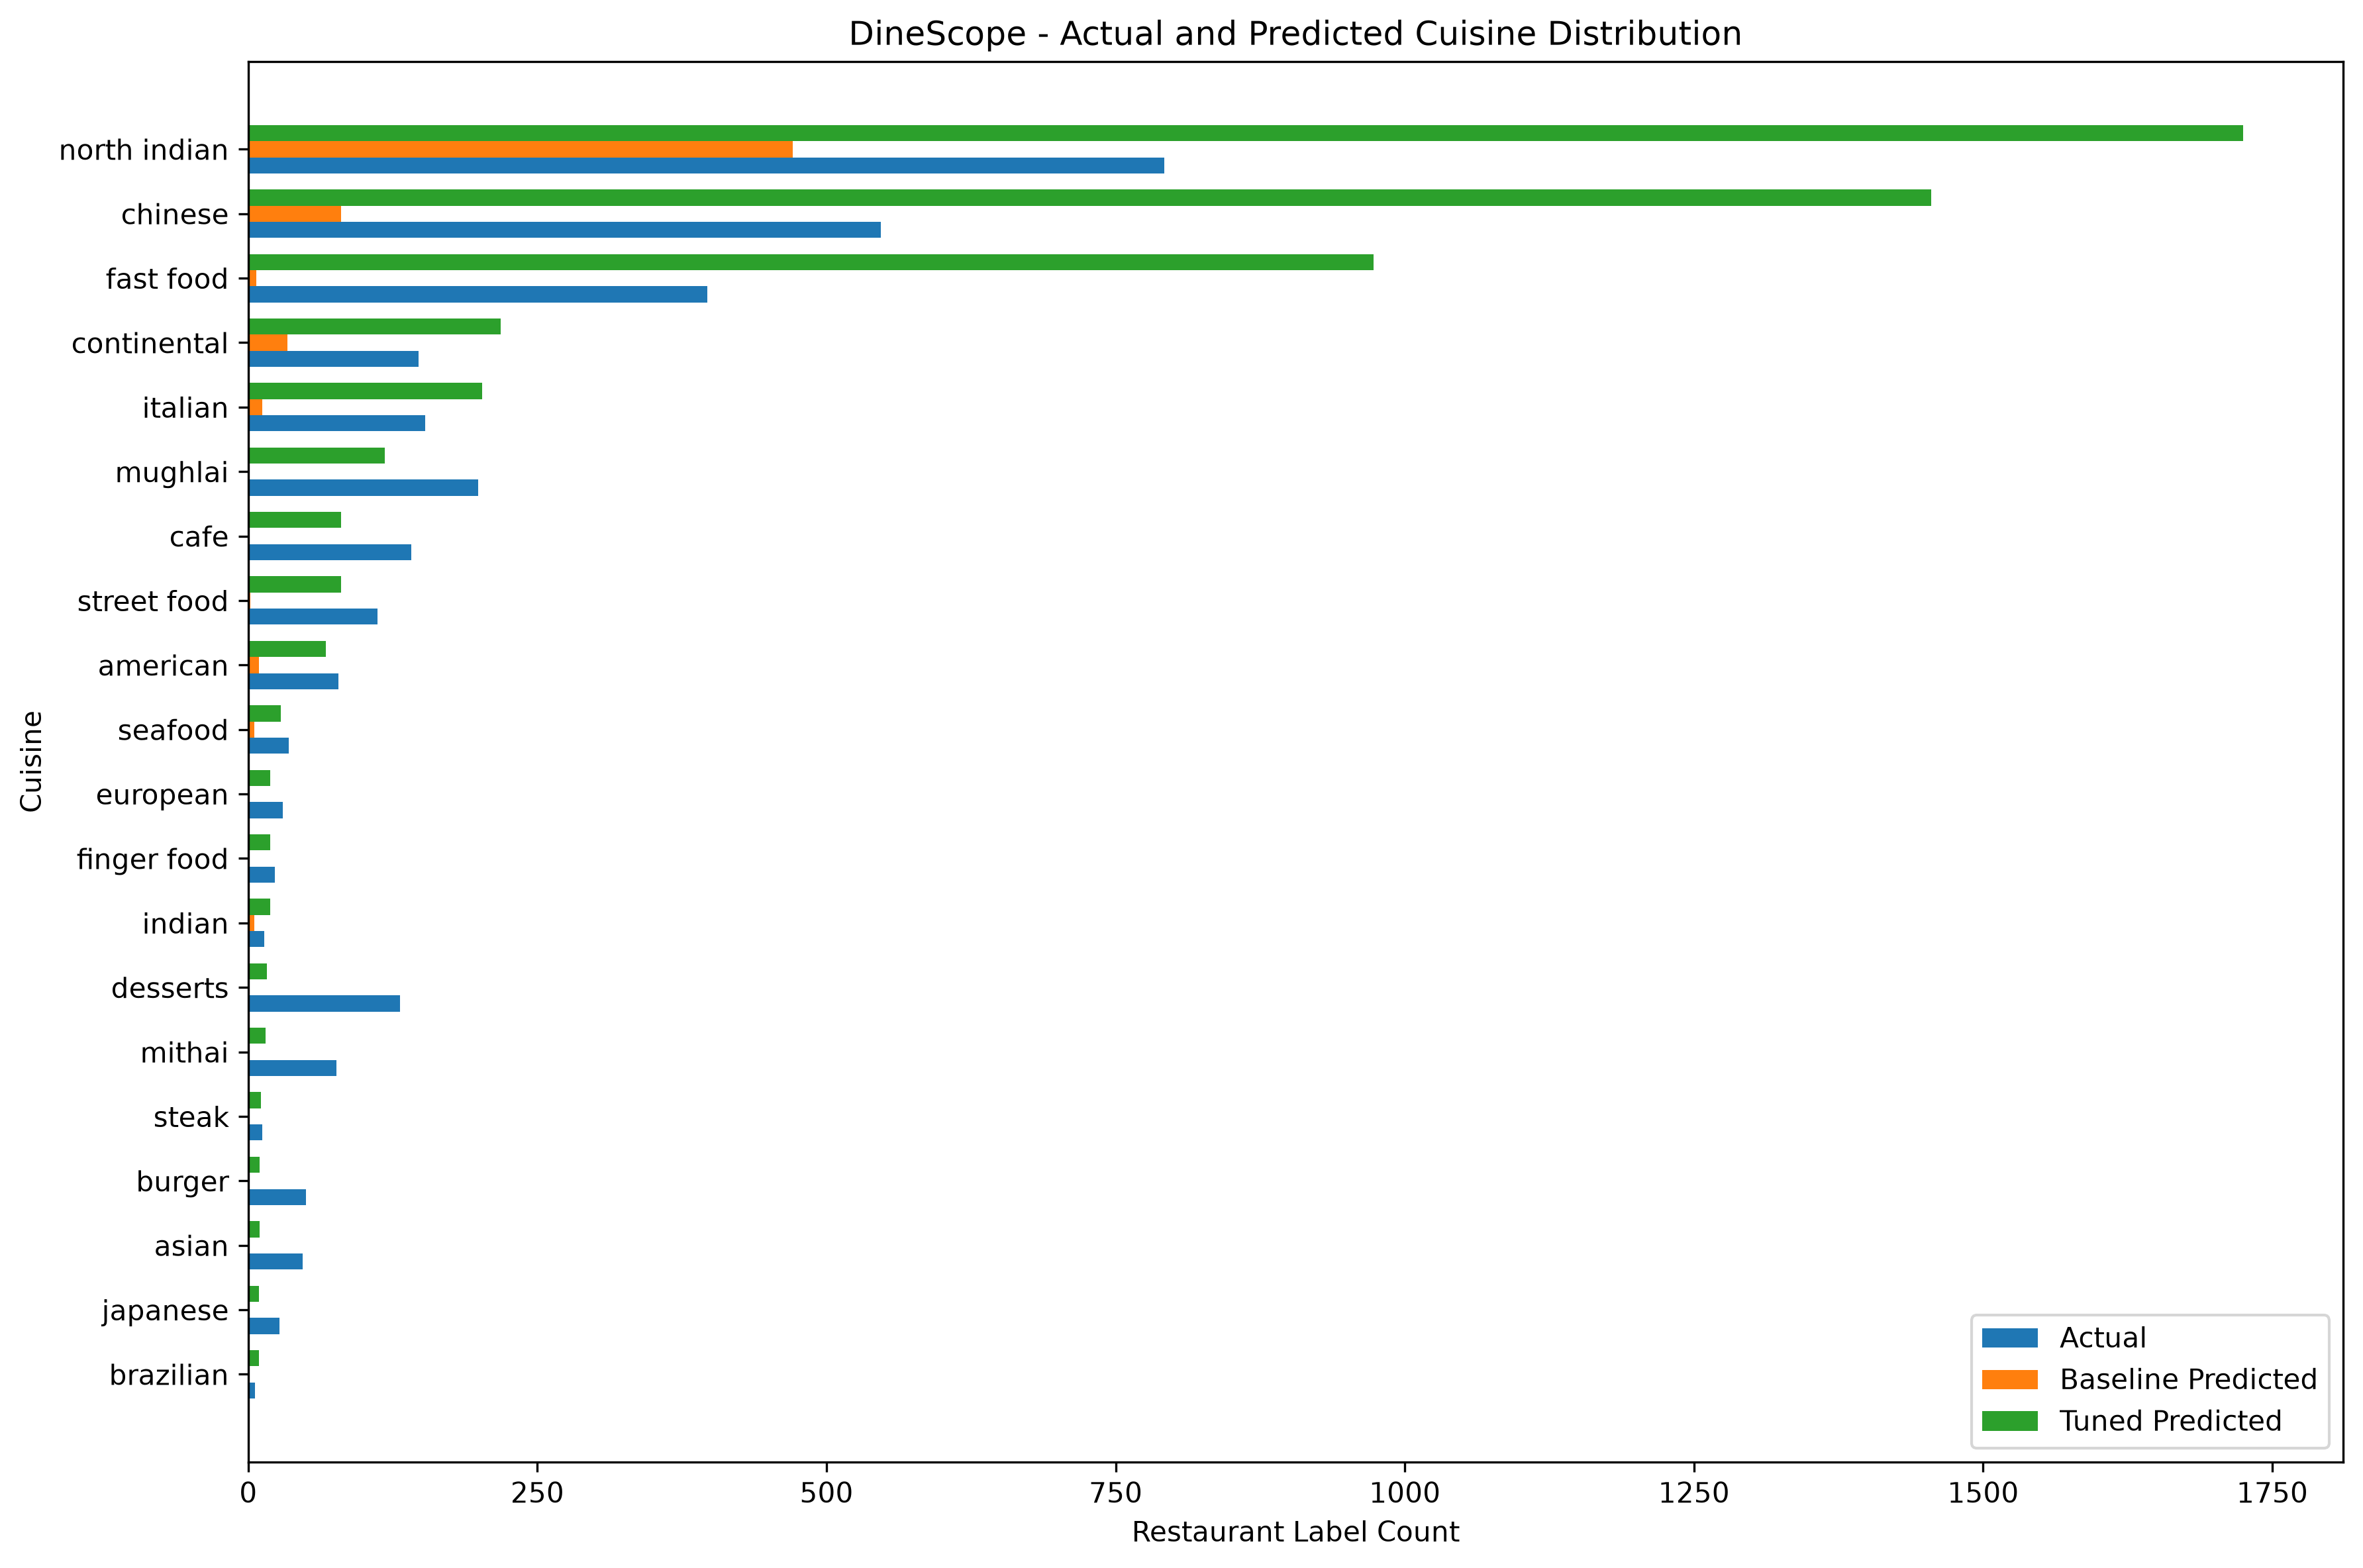

05_cuisine_prediction_count_distribution.png


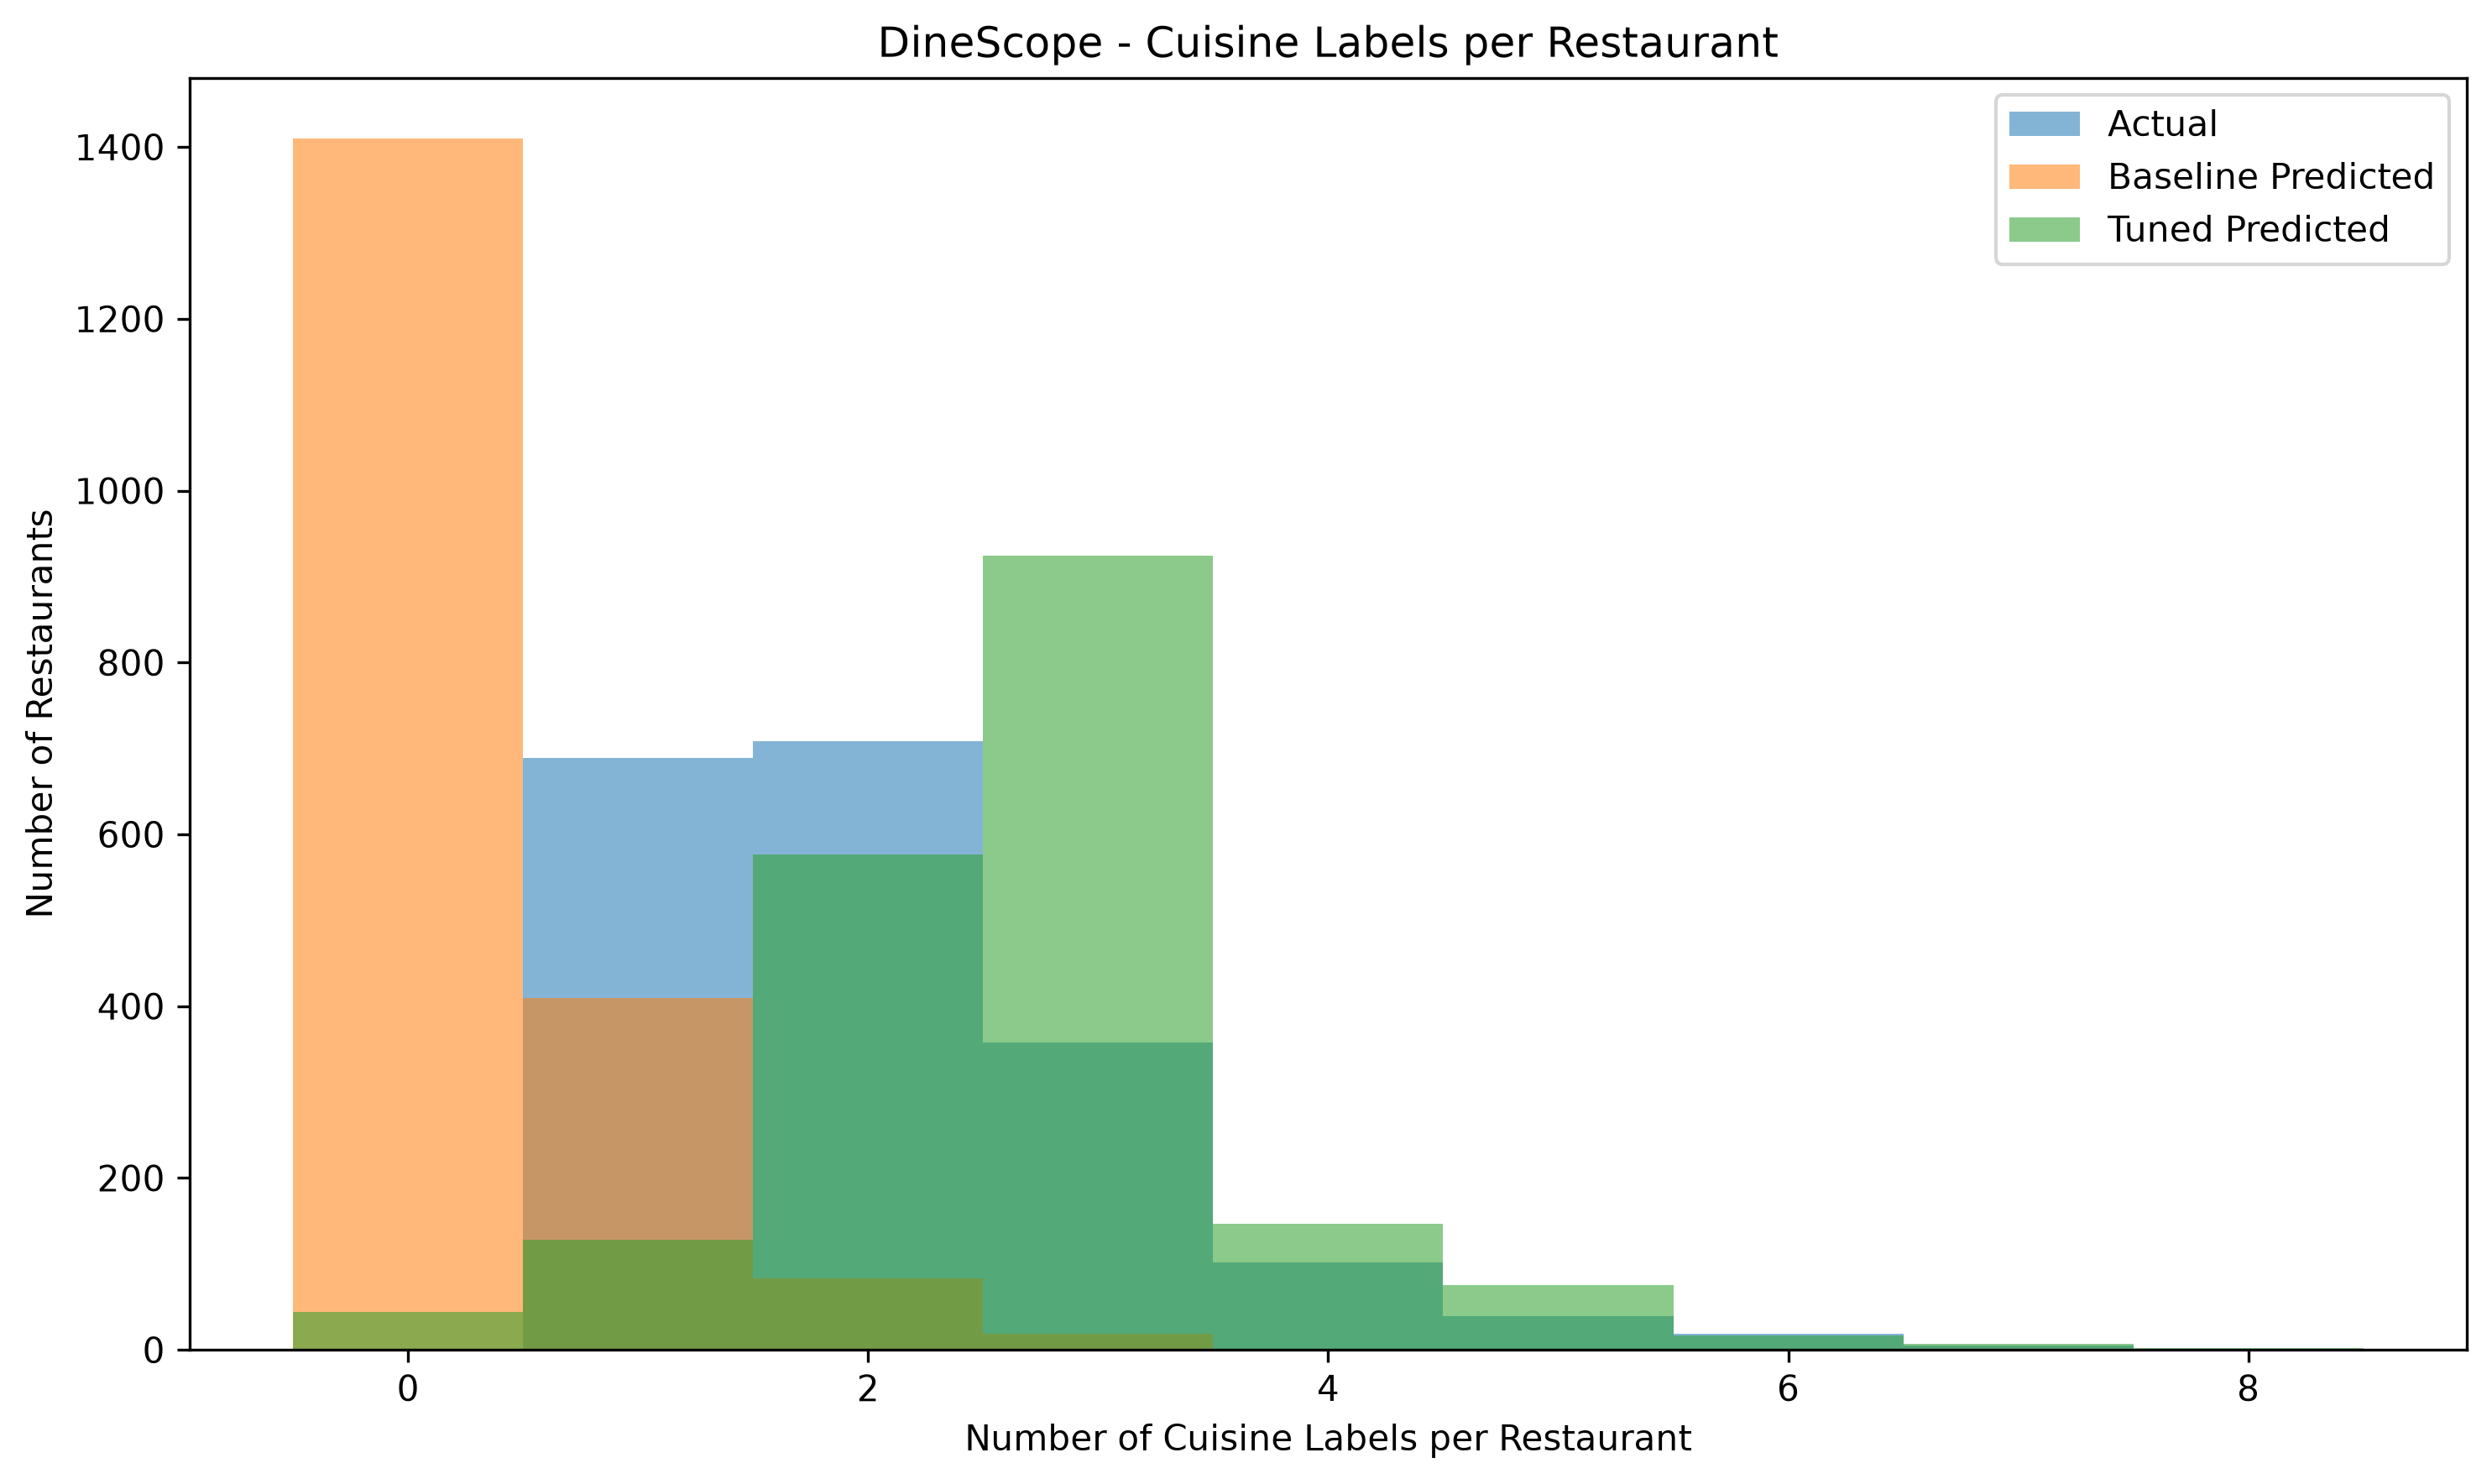

06_cuisine_probability_distribution.png


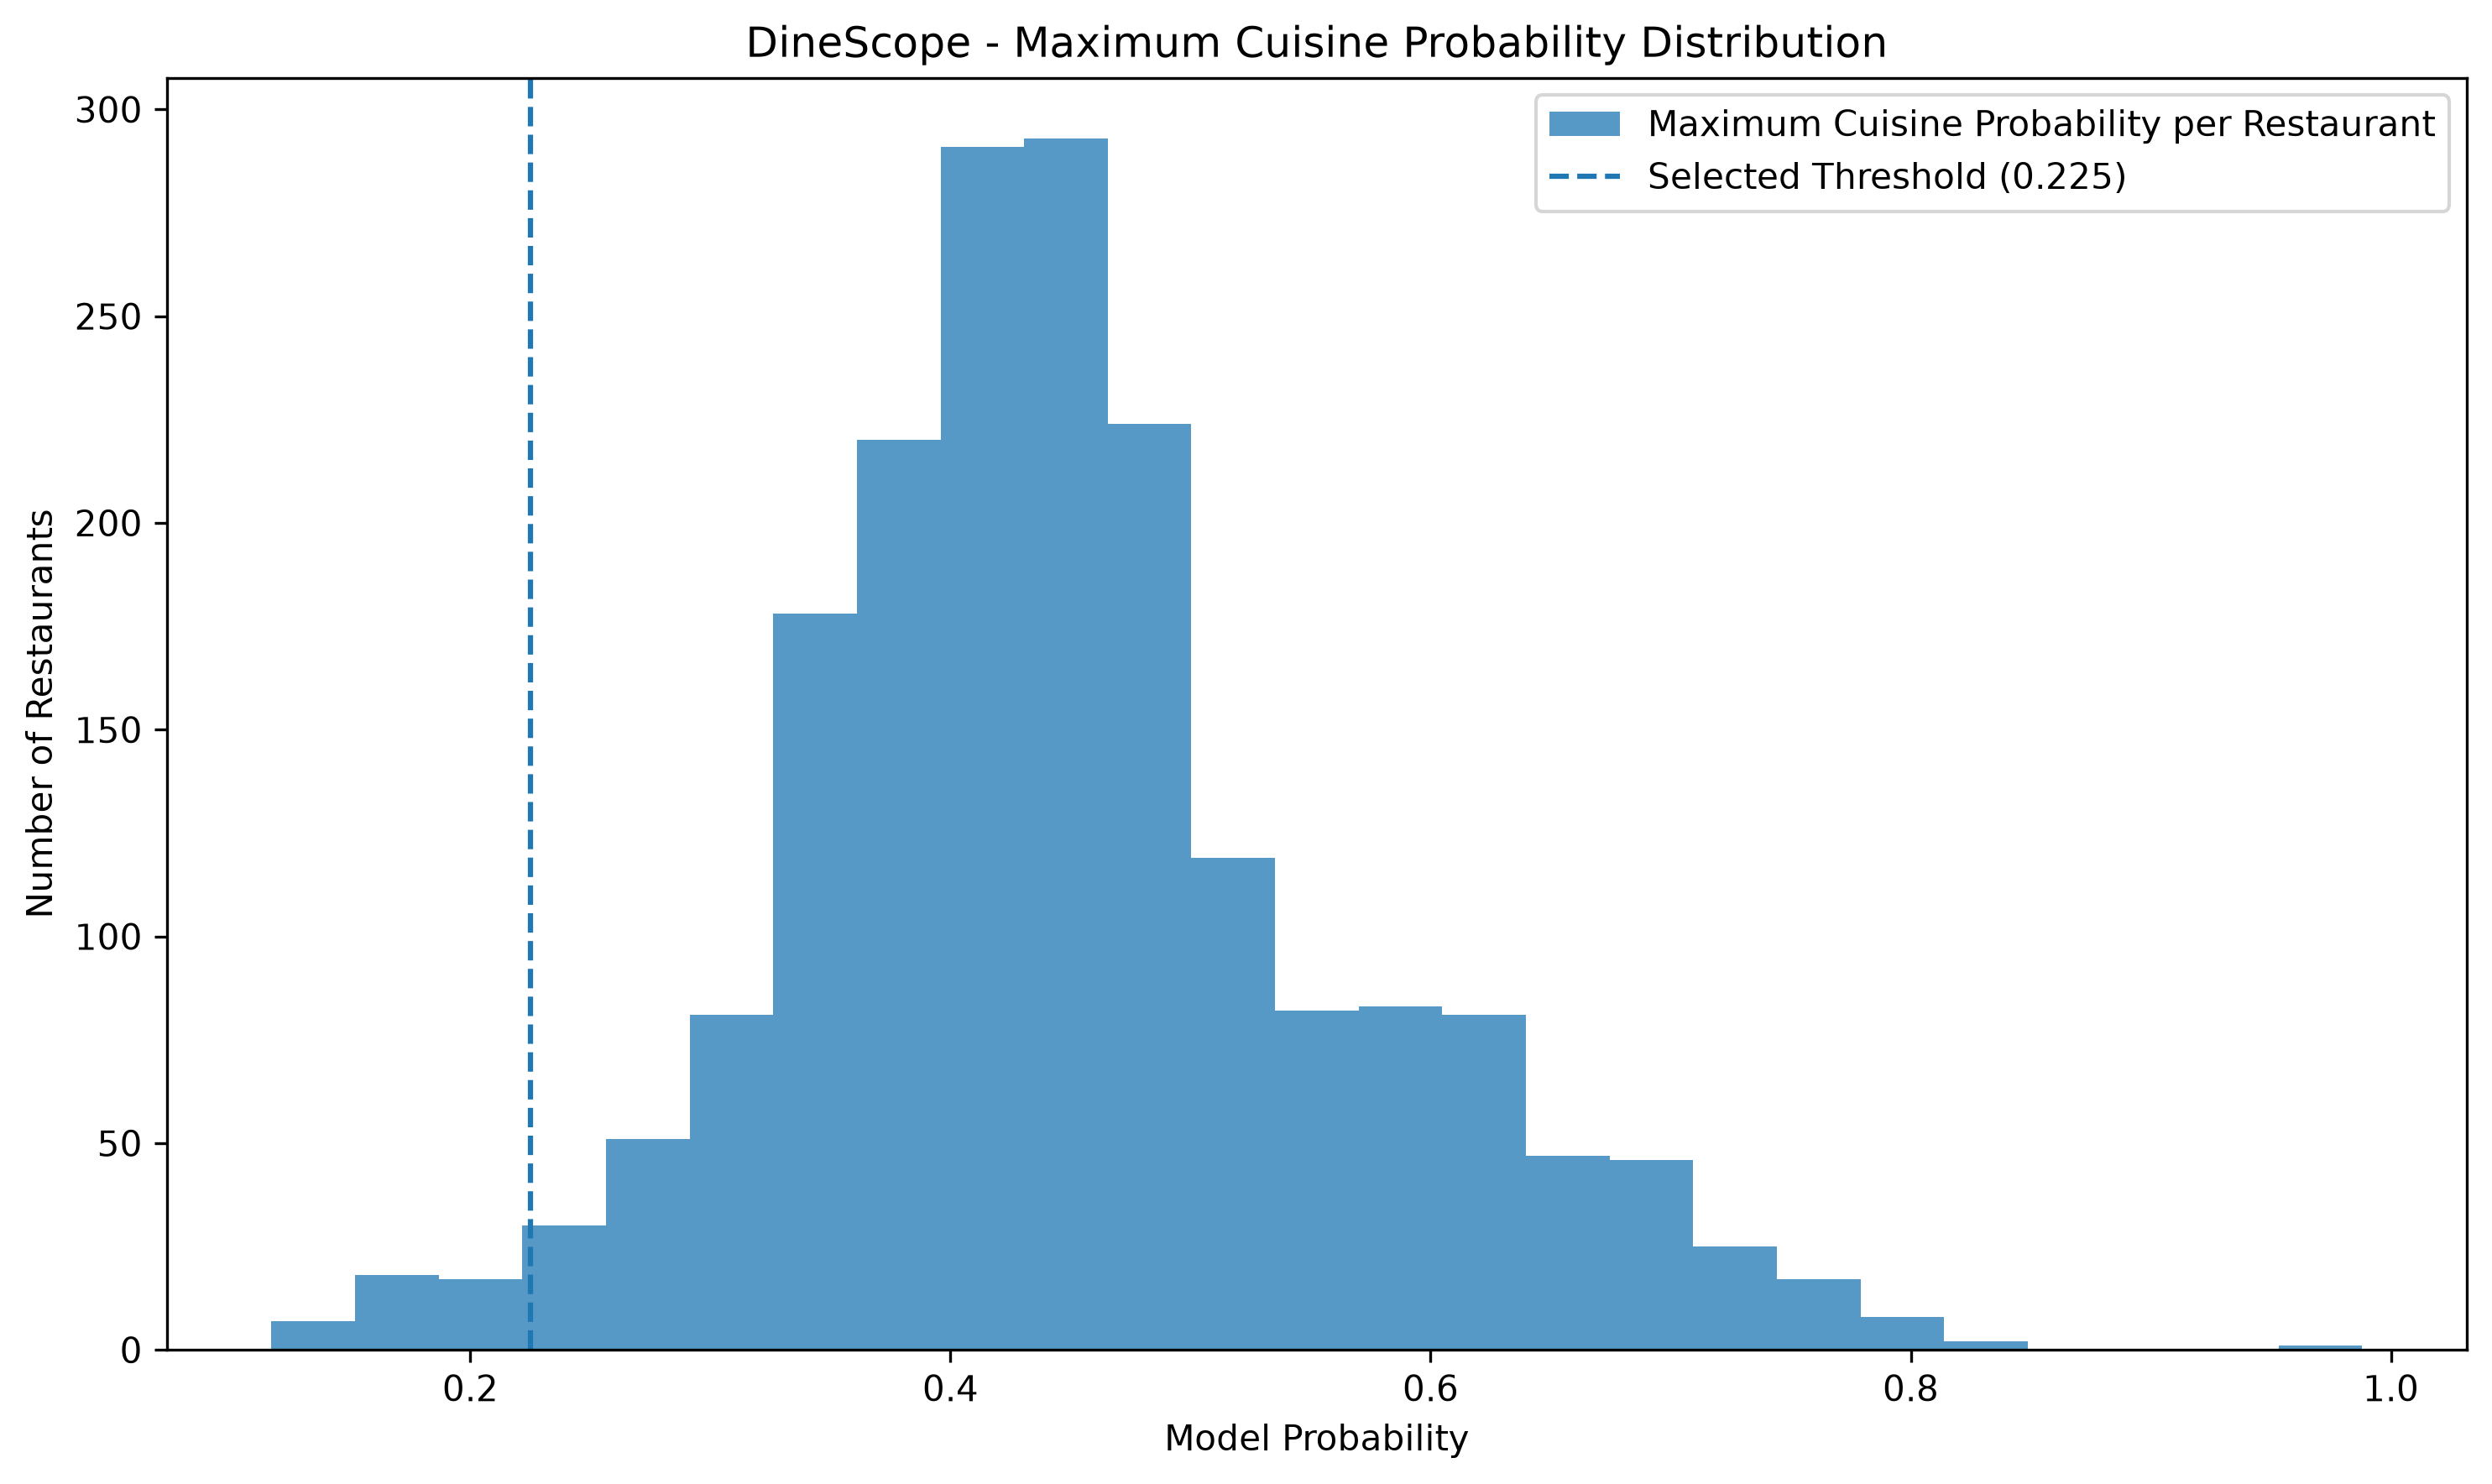

In [15]:
figure_files = [
    "01_cuisine_model_performance_comparison.png",
    "02_cuisine_per_class_f1_comparison.png",
    "03_cuisine_support_vs_f1.png",
    "04_cuisine_prediction_distribution.png",
    "05_cuisine_prediction_count_distribution.png",
    "06_cuisine_probability_distribution.png",
]
for filename in figure_files:
    image_path = FIGURES / filename
    if not image_path.exists():
        print("Missing figure:", image_path)
    else:
        print(filename)
        display(Image(filename=str(image_path)))

## 13. Review pipeline validation reports

Review the final text report, summary metrics and detailed per-cuisine results generated by Program 08.

In [16]:
report_path = REPORTS / "cuisine_final_classification_report.txt"
summary_path = REPORTS / "cuisine_final_classification_summary.csv"
comparison_path = REPORTS / "cuisine_final_model_comparison.csv"
per_class_path = REPORTS / "cuisine_final_per_class_metrics.csv"

if report_path.exists():
    print(report_path.read_text(encoding="utf-8"))
else:
    print("Final text report not found. Run Program 08.")

for path in [summary_path, comparison_path, per_class_path]:
    print("\\n" + path.name)
    if path.exists():
        display(pd.read_csv(path).head(20))
    else:
        print("File not found.")

DINESCOPE - RESTAURANT INTELLIGENCE & ANALYTICS
TASK 03: CUISINE CLASSIFICATION
FINAL VISUALIZATION AND REPORTING

1. DATASET AND CLASS INFORMATION
Test restaurants: 1921
Total cuisine classes: 145
Classes represented in test: 115
Classes absent from test: 30
Rare represented classes: 80

2. BASELINE MODEL PERFORMANCE
Micro Precision: 0.5585
Micro Recall: 0.0896
Micro F1: 0.1545
Macro F1 - All Classes: 0.0105
Macro F1 - Test-Supported: 0.0132
Weighted F1: 0.1211
Subset Accuracy: 0.0156
Hamming Loss: 0.0139

3. TUNED MODEL PERFORMANCE
Micro Precision: 0.3628
Micro Recall: 0.4775
Micro F1: 0.4124
Macro F1 - All Classes: 0.0706
Macro F1 - Test-Supported: 0.0891
Weighted F1: 0.3177
Subset Accuracy: 0.0432
Hamming Loss: 0.0192

4. MODEL COMPARISON
Micro F1 relative change: 166.99%
Selected threshold: 0.225
Baseline predicted labels: 632
Tuned predicted labels: 5184

5. PREDICTION PIPELINE
Restaurants with predictions: 1877
Restaurants without predictions: 44
Average predicted cuisines per r

,Metric,Value
0,Test Restaurants,1921
1,Total Cuisine Classes,145
2,Classes Represented in Test,115
3,Classes Absent from Test,30
4,Rare Classes in Test,80
5,Prediction Threshold,0.225
6,Baseline Micro F1,0.1544519798731131
7,Tuned Micro F1,0.41236435383097664
8,Baseline Macro F1 - All Classes,0.010490983568306448
9,Tuned Macro F1 - All Classes,0.07063100865836952


\ncuisine_final_model_comparison.csv


,Model,Micro Precision,Micro Recall,Micro F1,Macro F1 All Classes,Macro F1 Test-Supported,Weighted F1,Subset Accuracy,Hamming Loss,Predicted Labels,Actual Positive Labels,True Positives,False Positives,False Negatives,True Negatives
0,Baseline Logistic Regression,0.558544,0.089617,0.154452,0.010491,0.013228,0.121142,0.015617,0.013876,632,3939,353,279,3586,274327
1,Tuned Logistic Regression,0.362847,0.477532,0.412364,0.070631,0.089056,0.317695,0.043207,0.019246,5184,3939,1881,3303,2058,271303


\ncuisine_final_per_class_metrics.csv


,Cuisine,Test Support,Baseline Precision,Baseline Recall,Baseline F1,Tuned Precision,Tuned Recall,Tuned F1,F1 Improvement,Class Category
0,north indian,792,0.596603,0.354798,0.444972,0.455652,0.992424,0.624553,0.179581,Common
1,chinese,547,0.500000,0.073126,0.127592,0.352577,0.937843,0.512488,0.384896,Common
2,fast food,397,0.142857,0.002519,0.004950,0.289825,0.710327,0.411679,0.406728,Common
3,mughlai,199,0.000000,0.000000,0.000000,0.169492,0.100503,0.126183,0.126183,Common
4,italian,153,0.583333,0.045752,0.084848,0.262376,0.346405,0.298592,0.213743,Common
5,bakery,149,0.000000,0.000000,0.000000,0.142857,0.006711,0.012821,0.012821,Common
6,continental,147,0.411765,0.095238,0.154696,0.357798,0.530612,0.427397,0.272701,Common
7,cafe,141,0.000000,0.000000,0.000000,0.375000,0.212766,0.271493,0.271493,Common
8,desserts,131,0.000000,0.000000,0.000000,0.250000,0.030534,0.054422,0.054422,Common
9,south indian,127,0.000000,0.000000,0.000000,0.750000,0.023622,0.045802,0.045802,Common


## 14. Prediction examples and sample restaurant demonstration

Inspect a small set of restaurant predictions and their five highest model probability estimates. These are estimates from the classifier and have not been established as calibrated probabilities.

In [17]:
sample_records = []
for row_index in range(min(10, len(inference_input))):
    selected_indices = np.flatnonzero(inference_predictions[row_index] == 1)
    predicted_cuisines = [cuisine_classes[i] for i in selected_indices]
    top_indices = np.argsort(inference_probabilities[row_index])[::-1][:5]
    top_five = [
        {"cuisine": cuisine_classes[i],
         "probability_estimate": round(float(inference_probabilities[row_index, i]), 6)}
        for i in top_indices
    ]
    sample_records.append({
        "Source Row Index": source_row_indices[row_index],
        "Predicted Cuisine Count": len(predicted_cuisines),
        "Predicted Cuisines": ", ".join(predicted_cuisines) if predicted_cuisines else "No label crossed threshold",
        "Top 5 Probability Estimates": json.dumps(top_five, ensure_ascii=False),
    })
display(pd.DataFrame(sample_records))

,Source Row Index,Predicted Cuisine Count,Predicted Cuisines,Top 5 Probability Estimates
0,1,2,"filipino, japanese","[{""cuisine"": ""filipino"", ""probability_estimate..."
1,2,5,"european, filipino, japanese, seafood, sushi","[{""cuisine"": ""japanese"", ""probability_estimate..."
2,4,4,"european, filipino, japanese, sushi","[{""cuisine"": ""japanese"", ""probability_estimate..."
3,5,1,filipino,"[{""cuisine"": ""filipino"", ""probability_estimate..."
4,6,4,"asian, european, filipino, seafood","[{""cuisine"": ""european"", ""probability_estimate..."
5,11,1,filipino,"[{""cuisine"": ""filipino"", ""probability_estimate..."
6,13,1,filipino,"[{""cuisine"": ""filipino"", ""probability_estimate..."
7,16,3,"american, cafe, filipino","[{""cuisine"": ""filipino"", ""probability_estimate..."
8,18,2,"bakery, cafe","[{""cuisine"": ""cafe"", ""probability_estimate"": 0..."
9,21,7,"american, european, filipino, italian, japanes...","[{""cuisine"": ""american"", ""probability_estimate..."


## 15. Review interactive prediction history

This section reads the history created by `src/task_3_cuisine_classification/09_interactive_cuisine_prediction.py`. It does not launch the terminal application.

The history file is created when Program 09 is executed. If it is not available yet, run the application using the instructions in the final section of this notebook.

In [18]:
history_path = REPORTS / "interactive_cuisine_prediction_history.csv"

if history_path.exists():
    interactive_history = pd.read_csv(history_path)

    print("Interactive prediction records:", len(interactive_history))
    display(interactive_history.tail(10))

    print("\\nPrediction history columns:")
    print(interactive_history.columns.tolist())
else:
    print("Interactive prediction history is not available yet.")
    print("Run Program 09 using the command in Section 17.")

Interactive prediction records: 1


,Country Code,City,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes,Prediction Timestamp,Selected Threshold,Predicted Cuisines,Predicted Cuisine Count,Top Cuisine,Top Cuisine Confidence
0,1,New Delhi,Indian Rupees(Rs.),Yes,Yes,No,No,77.209,28.6139,800.0,2,4.1,250,2026-11-23T22:13:42,0.225,"[""north indian"", ""chinese""]",2,north indian,0.550883


\nPrediction history columns:
['Country Code', 'City', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Aggregate rating', 'Votes', 'Prediction Timestamp', 'Selected Threshold', 'Predicted Cuisines', 'Predicted Cuisine Count', 'Top Cuisine', 'Top Cuisine Confidence']


## 16. Conclusion

Task 3's multi-label cuisine-classification workflow includes dataset auditing, preprocessing, feature engineering, baseline model training, threshold tuning, model diagnostics, inference pipeline verification and final reporting.

### Key findings
- 145 cuisine classes were included in the label mapping.
- 115 classes were represented in the held-out test split; 30 were absent.
- The tuned Logistic Regression model achieved a Micro F1 of approximately **0.4124**, compared with approximately **0.1545** for the baseline.
- Recall improved substantially, while precision decreased.
- Program 07 reproduced Program 06 tuned predictions with 100% agreement.

### Limitations
1. Thirty cuisine classes were absent from the test split.
2. Many represented classes had limited test support.
3. Rare-class metrics should be interpreted cautiously.
4. Probability calibration has not been established.
5. The inference demonstration uses held-out test features, not an independent external dataset.
6. Exact agreement verifies implementation consistency, not generalization to unseen external restaurants.

**Primary model:** `models/task_3/tuned_cuisine_classification_model.joblib`  
**Feature preprocessor:** `models/task_3/cuisine_feature_preprocessor.joblib`  
**Selected threshold:** `0.225`

**Task 03 status:** Core implementation and local pipeline verification completed.

## 17. Interactive Cuisine Classification — Custom Input Testing

### Objective
Test the trained cuisine classification model using restaurant details entered manually by the user.

### Instructions
1. Open the VS Code integrated terminal.
2. Ensure the DineScope virtual environment is activated.
3. Run the interactive cuisine prediction application from the DineScope project root.
4. Enter all requested categorical and numerical restaurant details.
5. Review the predicted cuisine labels and their confidence scores.
6. Check which predictions cross the selected classification threshold.
7. Verify that the prediction history is saved successfully.

### Execute the application

Run the following command from the DineScope project root:

```powershell
python src/task_3_cuisine_classification/09_interactive_cuisine_prediction.py
```

### Expected outcome
- Accept 13 restaurant input features manually.
- Validate categorical and numerical inputs.
- Apply the saved feature preprocessor.
- Generate multi-label cuisine predictions using the tuned Logistic Regression model.
- Apply the saved global classification threshold.
- Display predicted cuisines and their confidence scores.
- Save the interactive prediction history to `reports/task_3/interactive_cuisine_prediction_history.csv`.

**Note:** This application uses the trained model, fitted feature preprocessor, cuisine label mapping and threshold generated during the Task 3 workflow. It does not retrain or retune the model.